In [27]:

# ==========================================
# NLP TASK 3 - PROJECT SETUP
# ==========================================

from google.colab import drive
from pathlib import Path

# Mount Google Drive
drive.mount('/content/drive')

# Define project directory
PROJECT_DIR = Path('/content/drive/MyDrive/NLP_Task3')

# Create project folders
folders = [
    "dataset/raw",
    "dataset/processed",
    "pretrained_model",
    "scratch_model",
    "results"
]

for folder in folders:
    (PROJECT_DIR / folder).mkdir(parents=True, exist_ok=True)

print("Project setup completed successfully!")
print(f"Project directory: {PROJECT_DIR}")

# Display created folders
for folder in folders:
    print(f"Created: {folder}")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project setup completed successfully!
Project directory: /content/drive/MyDrive/NLP_Task3
Created: dataset/raw
Created: dataset/processed
Created: pretrained_model
Created: scratch_model
Created: results


In [28]:

# ==========================================
# FIX: KAGGLE API AUTHENTICATION
# ==========================================

from google.colab import files
from pathlib import Path

# Upload credentials
uploaded = files.upload()

# Find the uploaded Kaggle JSON file
uploaded_name = next(
    (
        name for name in uploaded
        if Path(name).name.lower().startswith("kaggle")
        and name.lower().endswith(".json")
    ),
    None
)

if uploaded_name is None:
    raise FileNotFoundError(
        "Kaggle credentials file was not uploaded."
    )

# Create secure Kaggle directory
kaggle_dir = Path.home() / ".kaggle"
kaggle_dir.mkdir(parents=True, exist_ok=True)

# Save using the required filename
credentials_path = kaggle_dir / "kaggle.json"

credentials_path.write_bytes(
    uploaded[uploaded_name]
)

# Set secure permissions
credentials_path.chmod(0o600)

print("Kaggle API credentials configured successfully!")
print("Uploaded filename:", uploaded_name)
print("Credentials saved securely.")


Saving kaggle.json to kaggle (4).json
Kaggle API credentials configured successfully!
Uploaded filename: kaggle (4).json
Credentials saved securely.


In [29]:

# Check Kaggle API version
!kaggle --version

# List files available in Yelp Dataset
!kaggle datasets files -d yelp-dataset/yelp-dataset


Kaggle CLI 2.0.2
name                                       size  creationDate                
-----------------------------------  ----------  --------------------------  
Dataset_User_Agreement.pdf                80358  2022-03-17 22:59:04.213000  
yelp_academic_dataset_business.json   118863795  2022-03-17 22:59:06.534000  
yelp_academic_dataset_checkin.json    286958945  2022-03-17 22:59:15.158000  
yelp_academic_dataset_review.json    5341868833  2022-03-17 23:01:39.563000  
yelp_academic_dataset_tip.json        180604475  2022-03-17 23:00:06.425000  
yelp_academic_dataset_user.json      3363329011  2022-03-17 23:01:32.505000  


In [30]:

import shutil

# Check available Colab storage
total, used, free = shutil.disk_usage("/content")

print(f"Total Storage: {total / (1024**3):.2f} GB")
print(f"Used Storage: {used / (1024**3):.2f} GB")
print(f"Free Storage: {free / (1024**3):.2f} GB")


Total Storage: 107.72 GB
Used Storage: 7.14 GB
Free Storage: 100.56 GB


In [31]:

from pathlib import Path

RAW_DIR = Path("/content/yelp_raw")
RAW_DIR.mkdir(parents=True, exist_ok=True)

print("Raw data directory created:", RAW_DIR)


Raw data directory created: /content/yelp_raw


In [32]:

!kaggle datasets download \
    -d yelp-dataset/yelp-dataset \
    -f yelp_academic_dataset_review.json \
    -p /content/yelp_raw \
    --unzip


Dataset URL: https://www.kaggle.com/datasets/yelp-dataset/yelp-dataset
License(s): other
yelp_academic_dataset_review.json.zip: Skipping, found more recently modified local copy (use --force to force download)


In [33]:

import os

review_path = RAW_DIR / "yelp_academic_dataset_review.json"

if review_path.exists():
    size_gb = os.path.getsize(review_path) / (1024**3)
    print("Dataset downloaded successfully!")
    print(f"File size: {size_gb:.2f} GB")
    print(f"File path: {review_path}")
else:
    print("Dataset file not found. Please check the download.")


Dataset downloaded successfully!
File size: 4.98 GB
File path: /content/yelp_raw/yelp_academic_dataset_review.json


In [34]:

from pathlib import Path
import zipfile

zip_path = Path(
    "/content/yelp_raw/yelp_academic_dataset_review.json.zip"
)

extract_dir = Path("/content/yelp_raw")

print("ZIP exists:", zip_path.exists())

if zip_path.exists():
    with zipfile.ZipFile(zip_path, "r") as z:
        print("Files inside ZIP:", z.namelist())
        z.extractall(extract_dir)

    print("Extraction completed!")

review_path = extract_dir / "yelp_academic_dataset_review.json"

print("JSON exists:", review_path.exists())

if review_path.exists():
    print(f"JSON size: {review_path.stat().st_size / (1024**3):.2f} GB")


ZIP exists: True
Files inside ZIP: ['yelp_academic_dataset_review.json']
Extraction completed!
JSON exists: True
JSON size: 4.98 GB


In [35]:

import json
from itertools import islice
from pathlib import Path

# Dataset path
review_path = Path(
    "/content/yelp_raw/yelp_academic_dataset_review.json"
)

# Read first 5 records
with open(review_path, "r", encoding="utf-8") as file:
    sample_records = [
        json.loads(line)
        for line in islice(file, 5)
    ]

# Inspect dataset structure
print("Number of sample records:", len(sample_records))
print("\nAvailable columns:")
print(list(sample_records[0].keys()))

# Display sample reviews
for i, record in enumerate(sample_records, 1):
    print(f"\n========== Review {i} ==========")
    print("Stars:", record["stars"])
    print("Text:", record["text"][:200])
    print("Useful:", record["useful"])


Number of sample records: 5

Available columns:
['review_id', 'user_id', 'business_id', 'stars', 'useful', 'funny', 'cool', 'text', 'date']

========== Review 1 ==========
Stars: 3.0
Text: If you decide to eat here, just be aware it is going to take about 2 hours from beginning to end. We have tried it multiple times, because I want to like it! I have been to it's other locations in NJ 
Useful: 0

========== Review 2 ==========
Stars: 5.0
Text: I've taken a lot of spin classes over the years, and nothing compares to the classes at Body Cycle. From the nice, clean space and amazing bikes, to the welcoming and motivating instructors, every cla
Useful: 1

========== Review 3 ==========
Stars: 3.0
Text: Family diner. Had the buffet. Eclectic assortment: a large chicken leg, fried jalapeño, tamale, two rolled grape leaves, fresh melon. All good. Lots of Mexican choices there. Also has a menu with brea
Useful: 0

========== Review 4 ==========
Stars: 5.0
Text: Wow!  Yummy, different,  delici

In [36]:

# =====================================================
# NLP TASK 3 - YELP SENTIMENT ANALYSIS
# CELL 1: IMPORTS & CONFIGURATION
# =====================================================

import gc
import json
import os
from pathlib import Path

import pandas as pd
from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split
from IPython.display import display

# Reproducibility
RANDOM_SEED = 42

# Dataset configuration
CHUNK_SIZE = 50_000
SAMPLES_PER_CLASS = 50_000

CLASS_NAMES = ["negative", "neutral", "positive"]

STAR_TO_SENTIMENT = {
    1: "negative",
    2: "negative",
    3: "neutral",
    4: "positive",
    5: "positive"
}

LABEL2ID = {
    "negative": 0,
    "neutral": 1,
    "positive": 2
}

# Paths
RAW_PATH = Path(
    "/content/yelp_raw/yelp_academic_dataset_review.json"
)

PROJECT_DIR = Path(
    "/content/drive/MyDrive/NLP_Task3"
)

PROCESSED_DIR = PROJECT_DIR / "dataset" / "processed"

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

# Verify required files and directories
assert RAW_PATH.exists(), f"Dataset not found: {RAW_PATH}"
assert Path("/content/drive/MyDrive").exists(), "Google Drive is not mounted!"

print("Configuration completed successfully!")
print("Raw dataset:", RAW_PATH)
print("Processed data directory:", PROCESSED_DIR)
print("Samples per class:", SAMPLES_PER_CLASS)
print("Total target samples:", SAMPLES_PER_CLASS * 3)
print("Random seed:", RANDOM_SEED)


Configuration completed successfully!
Raw dataset: /content/yelp_raw/yelp_academic_dataset_review.json
Processed data directory: /content/drive/MyDrive/NLP_Task3/dataset/processed
Samples per class: 50000
Total target samples: 150000
Random seed: 42


In [37]:

# =====================================================
# CELL 2: SCAN FULL DATASET & SELECT BALANCED SAMPLE
# FIXED VERSION
# =====================================================

# Initialize reservoirs with explicit data types
reservoirs = {
    label: pd.DataFrame({
        "review_id": pd.Series(dtype="string"),
        "text": pd.Series(dtype="string"),
        "stars": pd.Series(dtype="int8"),
        "sentiment": pd.Series(dtype="string"),
        "_hash": pd.Series(dtype="uint64")
    })
    for label in CLASS_NAMES
}

# Full dataset statistics
star_counts = {star: 0 for star in range(1, 6)}

sentiment_counts = {
    label: 0 for label in CLASS_NAMES
}

total_rows_seen = 0
total_valid_records = 0

print("Starting full Yelp dataset scan...")

reader = pd.read_json(
    RAW_PATH,
    lines=True,
    chunksize=CHUNK_SIZE
)

for chunk_number, raw_chunk in enumerate(
    tqdm(reader, desc="Scanning Yelp Reviews"),
    start=1
):

    total_rows_seen += len(raw_chunk)

    # Keep only required columns
    chunk = raw_chunk[
        ["review_id", "text", "stars"]
    ].copy()

    # Normalize data types
    chunk["review_id"] = (
        chunk["review_id"]
        .astype("string")
        .str.strip()
    )

    chunk["text"] = (
        chunk["text"]
        .astype("string")
        .str.strip()
    )

    chunk["stars"] = pd.to_numeric(
        chunk["stars"],
        errors="coerce"
    )

    # Remove invalid records
    valid_mask = (
        chunk["review_id"].notna()
        & chunk["review_id"].ne("")
        & chunk["text"].notna()
        & chunk["text"].str.len().fillna(0).gt(0)
        & chunk["stars"].isin([1, 2, 3, 4, 5])
    )

    chunk = chunk.loc[valid_mask].copy()

    if chunk.empty:
        continue

    chunk["stars"] = chunk["stars"].astype("int8")

    # Convert ratings into sentiment labels
    chunk["sentiment"] = chunk["stars"].map(
        STAR_TO_SENTIMENT
    )

    total_valid_records += len(chunk)

    # Count original star ratings
    for star, count in chunk["stars"].value_counts().items():
        star_counts[int(star)] += int(count)

    # Count original sentiment classes
    for sentiment, count in chunk["sentiment"].value_counts().items():
        sentiment_counts[str(sentiment)] += int(count)

    # Generate deterministic hash
    chunk["_hash"] = pd.util.hash_pandas_object(
        chunk["review_id"],
        index=False,
        hash_key="0123456789123456"
    ).to_numpy(dtype="uint64")

    # Select lowest hash values per class
    for sentiment in CLASS_NAMES:

        candidates = chunk.loc[
            chunk["sentiment"] == sentiment,
            ["review_id", "text", "stars", "sentiment", "_hash"]
        ].copy()

        if not candidates.empty:

            combined = pd.concat(
                [reservoirs[sentiment], candidates],
                ignore_index=True
            )

            # Explicitly enforce numeric hash dtype
            combined["_hash"] = combined["_hash"].astype(
                "uint64"
            )

            reservoirs[sentiment] = (
                combined
                .nsmallest(
                    SAMPLES_PER_CLASS,
                    columns="_hash"
                )
                .reset_index(drop=True)
            )

    # Release temporary memory
    del raw_chunk, chunk

    if chunk_number % 20 == 0:
        gc.collect()

# Scan summary
print("\nFull dataset scan completed!")

print(f"Total rows scanned: {total_rows_seen:,}")
print(f"Valid reviews: {total_valid_records:,}")

print("\nSelected samples per class:")

for sentiment in CLASS_NAMES:

    selected_count = len(reservoirs[sentiment])

    print(f"{sentiment}: {selected_count:,}")

    if selected_count < SAMPLES_PER_CLASS:
        raise ValueError(
            f"Not enough records for {sentiment}. "
            f"Found {selected_count:,}"
        )

# Original star distribution
star_distribution = pd.DataFrame({
    "stars": list(star_counts.keys()),
    "count": list(star_counts.values())
})

print("\nOriginal Star Distribution:")
display(star_distribution)

# Original sentiment distribution
sentiment_distribution = pd.DataFrame({
    "sentiment": list(sentiment_counts.keys()),
    "count": list(sentiment_counts.values())
})

print("\nOriginal Sentiment Distribution:")
display(sentiment_distribution)

print("\nSampling completed successfully!")


Starting full Yelp dataset scan...


Scanning Yelp Reviews: 0it [00:00, ?it/s]


Full dataset scan completed!
Total rows scanned: 6,990,280
Valid reviews: 6,990,280

Selected samples per class:
negative: 50,000
neutral: 50,000
positive: 50,000

Original Star Distribution:


,stars,count
0,1,1069561
1,2,544240
2,3,691934
3,4,1452918
4,5,3231627



Original Sentiment Distribution:


,sentiment,count
0,negative,1613801
1,neutral,691934
2,positive,4684545



Sampling completed successfully!


In [38]:

# =====================================================
# CELL 3: BUILD BALANCED DATASET
# =====================================================

sampled_parts = []

for sentiment in CLASS_NAMES:

    sampled_parts.append(
        reservoirs[sentiment].copy()
    )

balanced_df = pd.concat(
    sampled_parts,
    ignore_index=True
)

# Remove sampling helper column
balanced_df = balanced_df.drop(columns=["_hash"])

# Remove duplicate reviews if any
balanced_df = balanced_df.drop_duplicates(
    subset=["review_id"]
).copy()

# Verify expected sample size
expected_size = SAMPLES_PER_CLASS * len(CLASS_NAMES)

if len(balanced_df) != expected_size:
    raise ValueError(
        f"Expected {expected_size:,} records, "
        f"but found {len(balanced_df):,}. "
        "Check duplicate review IDs."
    )

# Encode sentiment labels
balanced_df["label"] = (
    balanced_df["sentiment"]
    .map(LABEL2ID)
    .astype("int8")
)

balanced_df["stars"] = balanced_df["stars"].astype("int8")

# Keep a consistent column order
balanced_df = balanced_df[
    ["review_id", "text", "stars", "sentiment", "label"]
]

# Shuffle dataset
balanced_df = balanced_df.sample(
    frac=1,
    random_state=RANDOM_SEED
).reset_index(drop=True)

print("Balanced dataset created successfully!")

print("\nDataset shape:", balanced_df.shape)

print("\nSentiment distribution:")

display(
    balanced_df["sentiment"]
    .value_counts()
    .reindex(CLASS_NAMES)
    .rename("count")
    .to_frame()
)

print("\nLabel mapping:")
print(LABEL2ID)

print("\nFirst 5 records:")

display(
    balanced_df[
        ["stars", "sentiment", "label", "text"]
    ].head()
)


Balanced dataset created successfully!

Dataset shape: (150000, 5)

Sentiment distribution:


,count
sentiment,
negative,50000
neutral,50000
positive,50000



Label mapping:
{'negative': 0, 'neutral': 1, 'positive': 2}

First 5 records:


,stars,sentiment,label,text
0,3,neutral,1,Someone recommended this place for a good chee...
1,2,negative,0,First off I noticed many people are giving thi...
2,4,positive,2,"Cozy place, good food and fast service. I miss..."
3,5,positive,2,Love this place. It is all delicious. The gri...
4,4,positive,2,Get the Mary's special- roast beef on garlic c...


In [39]:

# =====================================================
# CELL 4: STRATIFIED TRAIN / VALIDATION / TEST SPLIT
# =====================================================

# First split: 90% train+validation, 10% test
train_val_df, test_df = train_test_split(
    balanced_df,
    test_size=0.10,
    random_state=RANDOM_SEED,
    stratify=balanced_df["label"]
)

# Second split: 80% train, 10% validation
# 1/9 of 90% = 10% of the full dataset
train_df, val_df = train_test_split(
    train_val_df,
    test_size=1/9,
    random_state=RANDOM_SEED,
    stratify=train_val_df["label"]
)

# Reset indices
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("Dataset splitting completed!")

print(f"Training records: {len(train_df):,}")
print(f"Validation records: {len(val_df):,}")
print(f"Testing records: {len(test_df):,}")

# Display class distribution for each split
def get_class_distribution(df):

    return (
        df["sentiment"]
        .value_counts()
        .reindex(CLASS_NAMES, fill_value=0)
    )

split_report = pd.DataFrame({
    "Train": get_class_distribution(train_df),
    "Validation": get_class_distribution(val_df),
    "Test": get_class_distribution(test_df)
})

print("\nClass distribution across splits:")

display(split_report)

# Verify there is no overlap between splits
train_ids = set(train_df["review_id"])
val_ids = set(val_df["review_id"])
test_ids = set(test_df["review_id"])

assert train_ids.isdisjoint(val_ids)
assert train_ids.isdisjoint(test_ids)
assert val_ids.isdisjoint(test_ids)

assert len(train_df) + len(val_df) + len(test_df) == len(balanced_df)

print("\nNo overlap detected between splits!")


Dataset splitting completed!
Training records: 120,000
Validation records: 15,000
Testing records: 15,000

Class distribution across splits:


,Train,Validation,Test
sentiment,,,
negative,40000,5000,5000
neutral,40000,5000,5000
positive,40000,5000,5000



No overlap detected between splits!


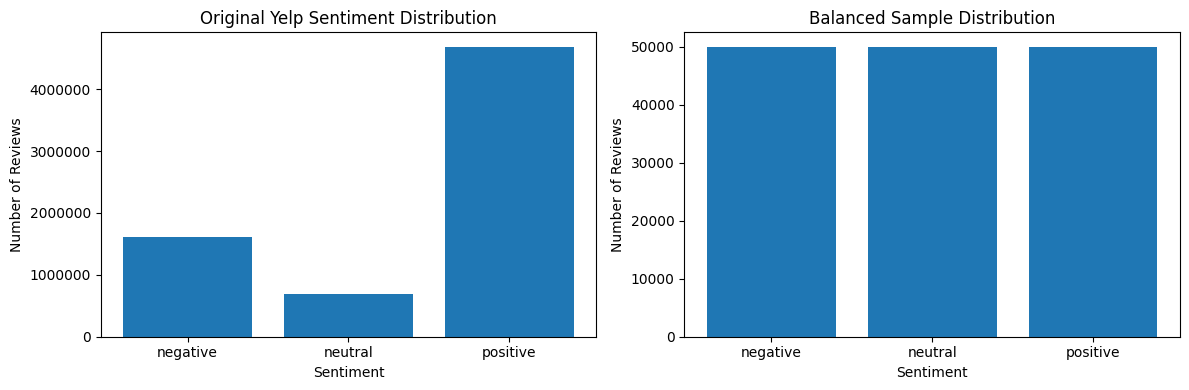

In [40]:

# =====================================================
# CELL 5: VISUALIZE DATA DISTRIBUTION
# =====================================================

import matplotlib.pyplot as plt

# Original sentiment distribution
original_values = [
    sentiment_counts[label]
    for label in CLASS_NAMES
]

# Balanced sample distribution
sample_values = [
    int((balanced_df["sentiment"] == label).sum())
    for label in CLASS_NAMES
]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(CLASS_NAMES, original_values)
axes[0].set_title("Original Yelp Sentiment Distribution")
axes[0].set_xlabel("Sentiment")
axes[0].set_ylabel("Number of Reviews")
axes[0].ticklabel_format(axis="y", style="plain")

axes[1].bar(CLASS_NAMES, sample_values)
axes[1].set_title("Balanced Sample Distribution")
axes[1].set_xlabel("Sentiment")
axes[1].set_ylabel("Number of Reviews")

plt.tight_layout()
plt.show()


In [41]:

# =====================================================
# CELL 6: SAVE DATASETS TO GOOGLE DRIVE
# =====================================================

dataset_tag = f"{len(balanced_df) // 1000}k"

split_files = {
    "train": (
        PROCESSED_DIR /
        f"yelp_train_{dataset_tag}_seed{RANDOM_SEED}.csv.gz"
    ),

    "validation": (
        PROCESSED_DIR /
        f"yelp_validation_{dataset_tag}_seed{RANDOM_SEED}.csv.gz"
    ),

    "test": (
        PROCESSED_DIR /
        f"yelp_test_{dataset_tag}_seed{RANDOM_SEED}.csv.gz"
    )
}

# Save splits
splits = {
    "train": train_df,
    "validation": val_df,
    "test": test_df
}

for split_name, df in splits.items():

    output_path = split_files[split_name]

    df.to_csv(
        output_path,
        index=False,
        compression="gzip",
        encoding="utf-8"
    )

    print(f"Saved {split_name}: {output_path.name}")

# Save original star distribution
star_distribution.to_csv(
    PROCESSED_DIR / "original_star_distribution.csv",
    index=False
)

# Save original sentiment distribution
sentiment_distribution.to_csv(
    PROCESSED_DIR / "original_sentiment_distribution.csv",
    index=False
)

# Save balanced sample distribution
sample_distribution = pd.DataFrame({
    "sentiment": CLASS_NAMES,
    "count": sample_values
})

sample_distribution.to_csv(
    PROCESSED_DIR / "balanced_sample_distribution.csv",
    index=False
)

# Save experiment metadata
manifest = {
    "project": "NLP Task 3 - Yelp Sentiment Analysis",
    "dataset": "Yelp Open Dataset",
    "source_url": "https://www.kaggle.com/datasets/yelp-dataset/yelp-dataset",
    "source_file": "yelp_academic_dataset_review.json",

    "total_rows_scanned": int(total_rows_seen),
    "valid_reviews_after_filtering": int(total_valid_records),

    "original_star_counts": {
        str(k): int(v)
        for k, v in star_counts.items()
    },

    "original_sentiment_counts": {
        k: int(v)
        for k, v in sentiment_counts.items()
    },

    "samples_per_class": int(SAMPLES_PER_CLASS),
    "total_sampled": int(len(balanced_df)),

    "label_mapping": LABEL2ID,

    "split_ratios": {
        "train": 0.80,
        "validation": 0.10,
        "test": 0.10
    },

    "split_sizes": {
        name: int(len(df))
        for name, df in splits.items()
    },

    "random_seed": RANDOM_SEED,

    "sampling_method": "Deterministic hash-based balanced sampling",

    "preprocessing": [
        "Remove missing review IDs",
        "Remove missing or empty review texts",
        "Keep valid star ratings from 1 to 5",
        "Map ratings to three sentiment classes",
        "Preserve original review text"
    ]
}

manifest_path = PROCESSED_DIR / "dataset_manifest.json"

with open(manifest_path, "w", encoding="utf-8") as file:
    json.dump(
        manifest,
        file,
        ensure_ascii=False,
        indent=4
    )

print("\nAll datasets and metadata saved successfully!")
print("Output directory:", PROCESSED_DIR)


Saved train: yelp_train_150k_seed42.csv.gz
Saved validation: yelp_validation_150k_seed42.csv.gz
Saved test: yelp_test_150k_seed42.csv.gz

All datasets and metadata saved successfully!
Output directory: /content/drive/MyDrive/NLP_Task3/dataset/processed


In [42]:

# =====================================================
# CELL 7: RELOAD AND VALIDATE SAVED DATASETS
# =====================================================

loaded_splits = {}

for split_name, file_path in split_files.items():

    assert file_path.exists(), (
        f"Missing file: {file_path}"
    )

    loaded_df = pd.read_csv(
        file_path,
        compression="gzip"
    )

    loaded_splits[split_name] = loaded_df

    print(
        f"{split_name}: {len(loaded_df):,} records | "
        f"{file_path.stat().st_size / (1024**2):.2f} MB"
    )

# Check required columns
required_columns = [
    "review_id",
    "text",
    "stars",
    "sentiment",
    "label"
]

for split_name, df in loaded_splits.items():

    assert all(
        column in df.columns
        for column in required_columns
    )

    assert df[required_columns].notna().all().all()

    assert df["text"].str.strip().ne("").all()

    assert set(df["label"].unique()).issubset({0, 1, 2})

# Check no review appears in more than one split
all_ids = pd.concat([
    loaded_splits["train"]["review_id"],
    loaded_splits["validation"]["review_id"],
    loaded_splits["test"]["review_id"]
], ignore_index=True)

assert all_ids.is_unique, "Duplicate review IDs found across splits!"

# Verify class distribution
for split_name, df in loaded_splits.items():

    print(f"\n{split_name.upper()} DISTRIBUTION")

    display(
        df["sentiment"]
        .value_counts()
        .reindex(CLASS_NAMES, fill_value=0)
        .rename("count")
        .to_frame()
    )

print("\nALL DATA VALIDATION CHECKS PASSED!")


train: 120,000 records | 31.23 MB
validation: 15,000 records | 3.91 MB
test: 15,000 records | 3.86 MB

TRAIN DISTRIBUTION


,count
sentiment,
negative,40000
neutral,40000
positive,40000



VALIDATION DISTRIBUTION


,count
sentiment,
negative,5000
neutral,5000
positive,5000



TEST DISTRIBUTION


,count
sentiment,
negative,5000
neutral,5000
positive,5000



ALL DATA VALIDATION CHECKS PASSED!


In [43]:

# =====================================================
# CELL 8: FINAL PROJECT DATASET SUMMARY
# =====================================================

print("=" * 55)
print("NLP TASK 3 - DATASET PREPARATION SUMMARY")
print("=" * 55)

print("\nDataset: Yelp Reviews")

print(f"Total rows scanned: {total_rows_seen:,}")
print(f"Valid reviews: {total_valid_records:,}")

print(f"\nBalanced sample: {len(balanced_df):,}")

print("\nSplit sizes:")

for name, df in loaded_splits.items():

    percentage = len(df) / len(balanced_df) * 100

    print(
        f"{name.capitalize():12s}: "
        f"{len(df):,} ({percentage:.1f}%)"
    )

print("\nLabel mapping:")

for label, label_id in LABEL2ID.items():

    print(f"{label}: {label_id}")

print("\nExample reviews:")

preview = loaded_splits["train"][
    ["text", "stars", "sentiment", "label"]
].head(5).copy()

preview["text"] = preview["text"].str.slice(0, 200)

display(preview)

print("\nSaved files:")

for path in split_files.values():
    print(path)

print("\nDataset preparation completed successfully!")


NLP TASK 3 - DATASET PREPARATION SUMMARY

Dataset: Yelp Reviews
Total rows scanned: 6,990,280
Valid reviews: 6,990,280

Balanced sample: 150,000

Split sizes:
Train       : 120,000 (80.0%)
Validation  : 15,000 (10.0%)
Test        : 15,000 (10.0%)

Label mapping:
negative: 0
neutral: 1
positive: 2

Example reviews:


,text,stars,sentiment,label
0,This place has drastically changed from our la...,3,neutral,1
1,Worst car wash EVER!! My car wasn't vacuumed ...,1,negative,0
2,The staff was friendly and I enjoyed the atmos...,3,neutral,1
3,Very flavorful ice cream. Did not try anything...,5,positive,2
4,I stumbled upon a micro/ brewery in New Hope a...,4,positive,2



Saved files:
/content/drive/MyDrive/NLP_Task3/dataset/processed/yelp_train_150k_seed42.csv.gz
/content/drive/MyDrive/NLP_Task3/dataset/processed/yelp_validation_150k_seed42.csv.gz
/content/drive/MyDrive/NLP_Task3/dataset/processed/yelp_test_150k_seed42.csv.gz

Dataset preparation completed successfully!
